# 2. Steady conduction and thermal resistance

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapter 1

Chapter 1 used one thermal resistance, that of a cylindrical layer of insulation. This
chapter builds the idea into a tool and applies it to three problems. A house wall in an
Astana winter: how much heat does it lose, and is its inner surface warm enough to stay
dry? An electric cable: why does a thin layer of insulation let it carry *more* current,
not less? And a fuel pellet in a nuclear reactor, where heat is generated inside the
solid and the conductivity changes by a factor of three between the surface and the
centre.

Each answer is checked against a finite-volume solution of the conduction equation that
makes none of the simplifications: layers, heat generation, a conductivity that depends
on temperature, and nonlinear boundary conditions.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import cumulative_trapezoid
from scipy.optimize import brentq

try:
    from engtransport import properties, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import properties, reference
from engtransport.plotting import panel_label, use_style

use_style()

## 2.1 Plane walls in series: a wall in an Astana winter

In a steady state with no heat generated inside, the same heat flux $q''$ crosses every
plane parallel to a wall. Fourier's law, $q'' = -k\,dT/dx$, then makes the temperature
linear in each layer, falling by $q''L/k$ across a layer of thickness $L$. The fall is the
flux times $R'' = L/k$, the *resistance per unit area* (m² K/W). At the two surfaces the
heat is exchanged with the room and with the outside air, by convection and radiation
together, with combined coefficients $h_i$ and $h_o$ and resistances $1/h_i$ and $1/h_o$.
The resistances are in series, so they add:

$$
q'' = \frac{T_i - T_o}{R''_{\rm tot}} = U\,(T_i - T_o), \qquad
R''_{\rm tot} = \frac{1}{h_i} + \sum_j \frac{L_j}{k_j} + \frac{1}{h_o}.
\tag{2.1}
$$

$U = 1/R''_{\rm tot}$ is the *U-value* of the wall, the number building codes regulate.
The temperature of the inner surface follows from the first resistance alone:

$$
T_{si} = T_i - \frac{q''}{h_i} = T_i - \frac{U}{h_i}\,(T_i - T_o).
\tag{2.2}
$$

$T_{si}$ matters for two reasons. A cold wall feels uncomfortable even in warm air, and
if $T_{si}$ falls below the dew point of the room air, water condenses on the wall and
mould follows. Room air at 20 °C and 50 % relative humidity has a dew point of 9.3 °C
(from the Magnus formula for the vapour pressure of water, in `properties.dew_point`).

Two layers that touch are never in perfect contact. Rough surfaces meet at a few points,
and the gaps between them add a *contact resistance*, between about $10^{-5}$ and
$10^{-3}$ m² K/W depending on the roughness, the pressure and what fills the gaps. It is
negligible beside the layers of a wall, but not between two pieces of metal (Exercise 3).

Take a wall of 380 mm of solid brick, plastered inside and insulated outside with 150 mm
of mineral wool under a thin render. The values below are typical; real materials vary
by 10–20 %. The room is at 20 °C and the outside air at −35 °C. The usual combined
coefficients are $h_i = 8$ W/(m² K) inside (still air) and $h_o = 23$ W/(m² K) outside
(wind).

In [2]:
layers = [("plaster", 0.020, 0.80), ("brick", 0.380, 0.70), ("mineral wool", 0.150, 0.040),
          ("render", 0.010, 0.80)]                       # name, thickness (m), k (W/(m K))
h_i, h_o, T_i, T_o = 8.0, 23.0, 273.15 + 20.0, 273.15 - 35.0
T_dew = properties.dew_point(T_i, 0.50)


def wall(layers, h_i=h_i):
    """U-value, heat flux and inner surface temperature of a layered wall, Eqs. (2.1)-(2.2)."""
    R = 1 / h_i + sum(L / k for _, L, k in layers) + 1 / h_o
    q = (T_i - T_o) / R
    return 1 / R, q, T_i - q / h_i


bare = [lay for lay in layers if lay[0] != "mineral wool"]
for name, lay in (("insulated wall", layers), ("brick without insulation", bare)):
    U, q, T_si = wall(lay)
    print(f"{name:25s}: U = {U:.3f} W/(m2 K), q'' = {q:5.1f} W/m2, inner surface {T_si - 273.15:5.1f} C")
print(f"dew point of room air at 20 C, 50 % RH: {T_dew - 273.15:.1f} C")
R_parts = [1 / h_i] + [L / k for _, L, k in layers] + [1 / h_o]
print("share of each resistance (inside film, plaster, brick, wool, render, outside film):",
      ", ".join(f"{100 * r / sum(R_parts):.1f} %" for r in R_parts))

insulated wall           : U = 0.222 W/(m2 K), q'' =  12.2 W/m2, inner surface  18.5 C
brick without insulation : U = 1.335 W/(m2 K), q'' =  73.4 W/m2, inner surface  10.8 C
dew point of room air at 20 C, 50 % RH: 9.3 C
share of each resistance (inside film, plaster, brick, wool, render, outside film): 2.8 %, 0.6 %, 12.1 %, 83.4 %, 0.3 %, 1.0 %


The insulated wall has $U = 0.22$ W/(m² K) and loses 12 W per square metre; its inner
surface is at 18.5 °C, comfortably above the dew point. Without the insulation the same
brick wall loses six times as much, 73 W/m², and its inner surface is at 10.8 °C, only
1.5 K above the dew point. In a corner, where the air moves less and $h_i$ is lower,
the surface is colder still, and this is where the black mould of old flats appears
(Figure 2.1b). The mineral wool carries 83 % of the resistance of the insulated wall. Its
place on the *outside* matters too: the brick then stays warm, and the dew point of the
vapour that diffuses through the wall is reached in the wool, not in the masonry.

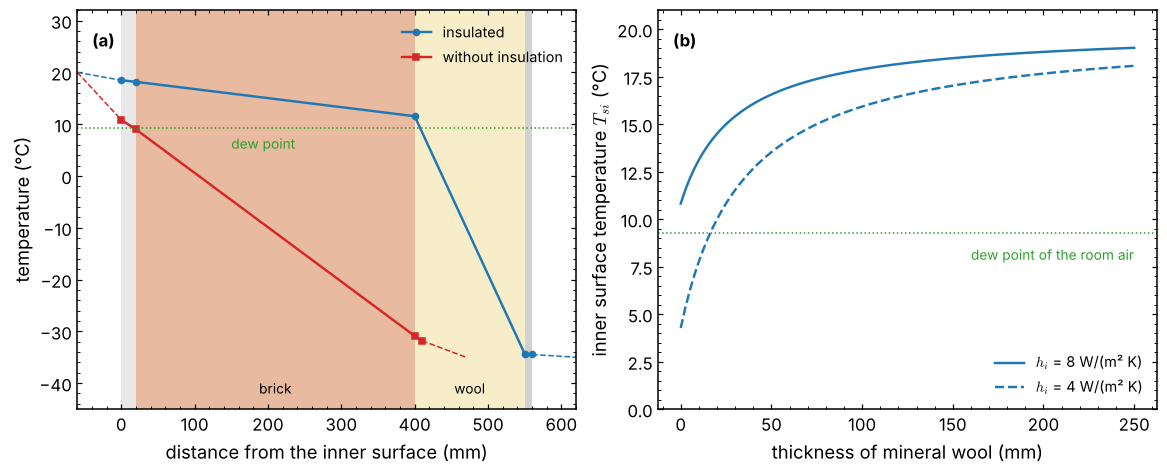

In [3]:
x_edges = np.cumsum([0.0] + [L for _, L, _ in layers])


def wall_profile(lay, h_i=h_i):
    """Positions and temperatures at the layer boundaries, from the room to the outside."""
    U, q, T_si = wall(lay, h_i)
    xs, Ts, x, T = [0.0], [T_si], 0.0, T_si
    for _, L, k in lay:
        x, T = x + L, T - q * L / k
        xs.append(x)
        Ts.append(T)
    return np.array(xs), np.array(Ts)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
colours = {"plaster": "0.85", "brick": "#d98c5f", "mineral wool": "#f3e3a6", "render": "0.7"}
for (name, L, _), x0 in zip(layers, x_edges[:-1]):
    ax1.axvspan(x0 * 1e3, (x0 + L) * 1e3, color=colours[name], alpha=0.6, lw=0)
for lay, style, label in ((layers, "C0-o", "insulated"), (bare, "C3-s", "without insulation")):
    xs, Ts = wall_profile(lay)
    xs_plot = xs if lay is layers else np.concatenate((xs[:2], xs[2:3], [x_edges[-1]]))
    if lay is bare:                                 # draw the render where it is in the insulated wall
        xs_plot = np.array([0.0, 0.020, 0.400, 0.410])
    ax1.plot(xs_plot * 1e3, Ts - 273.15, style, ms=4, label=label)
    ax1.plot([-60, 0], [T_i - 273.15, Ts[0] - 273.15], style[:2], lw=1, ls="--")
    ax1.plot([xs_plot[-1] * 1e3, xs_plot[-1] * 1e3 + 60], [Ts[-1] - 273.15, T_o - 273.15], style[:2], lw=1, ls="--")
ax1.axhline(T_dew - 273.15, color="C2", lw=1.0, ls=":")
ax1.text(150, T_dew - 273.15 - 4.0, "dew point", color="C2", fontsize=9)
for name, x0, L in (("brick", 0.02, 0.38), ("wool", 0.40, 0.15)):
    ax1.text((x0 + L / 2) * 1e3, -42, name, ha="center", fontsize=9)
ax1.set_xlim(-60, 620)
ax1.set_ylim(-45, 32)
ax1.set_xlabel("distance from the inner surface (mm)")
ax1.set_ylabel("temperature (°C)")
ax1.legend(loc="upper right")
panel_label(ax1, "(a)")

thick = np.linspace(0, 0.25, 101)
for hh, style in ((8.0, "C0-"), (4.0, "C0--")):
    T_si = [wall([lay if lay[0] != "mineral wool" else ("mineral wool", t, 0.040) for lay in layers], h_i=hh)[2]
            for t in thick]
    ax2.plot(thick * 1e3, np.array(T_si) - 273.15, style, label=rf"$h_i$ = {hh:.0f} W/(m² K)")
ax2.axhline(T_dew - 273.15, color="C2", lw=1.0, ls=":")
ax2.text(160, T_dew - 273.15 - 1.4, "dew point of the room air", color="C2", fontsize=9)
ax2.set_xlabel("thickness of mineral wool (mm)")
ax2.set_ylabel(r"inner surface temperature $T_{si}$ (°C)")
ax2.set_ylim(0, 21)
ax2.legend(loc="lower right")
panel_label(ax2, "(b)")
plt.show()

**Figure 2.1.** (a) Temperature through the wall from the room (left) to the outside air,
with and without 150 mm of mineral wool; the dashed lines are the drops across the air
films at the two surfaces. (b) Temperature of the inner surface against the thickness of
insulation, for an open wall ($h_i = 8$ W/(m² K)) and for a corner where the air hardly
moves ($h_i = 4$). Below the dotted line water condenses on the wall.

## 2.2 Cylinders and the critical radius: an electric cable

For radial conduction through a cylindrical layer, Chapter 1 gave the resistance per
metre $R' = \ln(r_2/r_1)/2\pi k$. A wire of radius $r_1$ at temperature $T_1$, covered with
insulation of conductivity $k$ to radius $r_2$ and cooled by air at $T_\infty$ with a
combined coefficient $h$, loses

$$
q' = \frac{T_1 - T_\infty}{\dfrac{\ln(r_2/r_1)}{2\pi k} + \dfrac{1}{2\pi r_2 h}}
\tag{2.3}
$$

per metre. Adding insulation does two things: it adds conduction resistance, which
grows like $\ln r_2$, and it enlarges the outer surface, which reduces the outer
resistance like $1/r_2$. Setting $dq'/dr_2 = 0$ gives the *critical radius*

$$
r_{\rm cr} = \frac{k}{h},
\tag{2.4}
$$

at which the heat loss is largest. Below $r_{\rm cr}$, more insulation *increases* the heat
loss. For a pipe of Chapter 1, $r_{\rm cr} = 0.045/25 = 1.8$ mm, far inside the pipe, so
insulation always helps. For a thin wire covered in plastic it is the other way round:
PVC has $k \approx 0.19$ W/(m K), and with $h \approx 10$ W/(m² K) in still air (convection
and radiation together), $r_{\rm cr} = 19$ mm, far larger than any cable.

The insulation therefore helps a cable to lose its heat. That heat is generated by the
current $I$: the resistance per metre is $\rho_e/A$, with $A$ the cross-section of the
copper and $\rho_e$ its resistivity, so the heat generated per metre is $I^2\rho_e/A$. PVC
must not be heated above 70 °C, so the largest current the cable can carry steadily, its
*ampacity*, follows from $q'$ at $T_1 = 70$ °C:

$$
I_{\max} = \left[\frac{(T_{\max} - T_\infty)\,A}{\rho_e\,R'_{\rm tot}}\right]^{1/2},
\tag{2.5}
$$

where $R'_{\rm tot}$ is the denominator of Eq. (2.3). The resistivity of annealed copper is
$1.7241\times10^{-8}$ Ω m at 20 °C and rises by 0.393 % per kelvin (the international
standard for copper), to $2.06\times10^{-8}$ Ω m at 70 °C. Take a copper conductor of
16 mm² ($r_1 = 2.26$ mm) in air at 30 °C.

In [4]:
A_cu = 16e-6
r_c = math.sqrt(A_cu / math.pi)
k_pvc, h_air, T_amb, T_max = 0.19, 10.0, 273.15 + 30.0, 273.15 + 70.0
rho_e = 1.7241e-8 * (1 + 0.00393 * (70.0 - 20.0))


def R_cable(r2, h=h_air, k=k_pvc):
    return math.log(r2 / r_c) / (2 * math.pi * k) + 1 / (2 * math.pi * r2 * h)


def ampacity(r2, h=h_air):
    return math.sqrt((T_max - T_amb) * A_cu / (rho_e * R_cable(r2, h)))


r_cr = k_pvc / h_air
print(f"conductor radius {1e3 * r_c:.2f} mm, critical radius k/h = {1e3 * r_cr:.0f} mm")
print(f"bare conductor: {ampacity(r_c):.0f} A;  1.2 mm of PVC: {ampacity(r_c + 1.2e-3):.0f} A;"
      f"  at the critical radius: {ampacity(r_cr):.0f} A")

conductor radius 2.26 mm, critical radius k/h = 19 mm
bare conductor: 66 A;  1.2 mm of PVC: 79 A;  at the critical radius: 109 A


A bare 16 mm² conductor could carry 66 A before reaching 70 °C. The usual 1.2 mm of PVC
raises this to 79 A, because the larger surface sheds heat more easily than the plastic
resists it. A cable as thick as the critical radius, 38 mm across, would carry 109 A.
Thickness is limited by cost, flexibility and the space in cable trays, not by heat.
Figure 2.2a shows the heat loss against the outer radius for three coefficients; each
curve has its maximum at $r_{\rm cr} = k/h$.

## 2.3 Heat generated inside: a wire and a fuel pellet

When heat is generated at a rate $\dot q$ per unit volume, the energy balance on a thin
shell between $r$ and $r + dr$ of a long cylinder becomes

$$
\frac{1}{r}\frac{d}{dr}\!\left(r\,k\,\frac{dT}{dr}\right) + \dot q = 0 .
\tag{2.6}
$$

With constant $k$ and a finite temperature on the axis, the solution is a parabola. Its
rise from the surface $r = R$ to the centre is

$$
T(r) = T_s + \frac{\dot q\,(R^2 - r^2)}{4k}, \qquad
T_c - T_s = \frac{\dot q R^2}{4k} = \frac{q'}{4\pi k},
\tag{2.7}
$$

where $q' = \dot q\pi R^2$ is the heat generated per metre. The rise depends only on the
heat per metre and the conductivity, not on the radius.

In the copper of the cable carrying 79 A, $q' = 8.1$ W/m and $k = 400$ W/(m K), so the centre is
$q'/4\pi k = 0.002$ K warmer than the surface: the conductor is isothermal, as assumed
above. A fuel pellet of a pressurised-water reactor is the opposite case. Uranium
dioxide conducts heat badly, $k \approx 2$–6 W/(m K), and a pellet of radius 4.1 mm
generates around $q' = 20$ kW per metre of rod. Equation (2.7) with $k = 3$ W/(m K) gives
a centre about 530 K hotter than the surface, independent of the pellet radius. Making
the pellets thinner would not help; only a lower power per metre does.

## 2.4 Conductivity that depends on temperature: the Kirchhoff transform

Over 500 K the conductivity of uranium dioxide cannot be taken constant. It falls from
5.8 W/(m K) at 500 K to 2.1 W/(m K) near 2000 K, as the phonons that carry the heat scatter
more often, and then rises again as electrons and holes start to carry heat. Equation (2.6)
is then nonlinear. The *Kirchhoff transform* makes it linear again. Define

$$
\Theta(T) = \int_{T_{\rm ref}}^{T} k(T')\,dT', \qquad \text{so that} \qquad
k\,\frac{dT}{dr} = \frac{d\Theta}{dr}.
\tag{2.8}
$$

In terms of $\Theta$, Eq. (2.6) is the equation for constant $k = 1$, and Eq. (2.7) holds
for $\Theta$:

$$
\Theta(T(r)) = \Theta(T_s) + \frac{q'}{4\pi}\left(1 - \frac{r^2}{R^2}\right), \qquad
\int_{T_s}^{T_c} k(T)\,dT = \frac{q'}{4\pi}.
\tag{2.9}
$$

The integral of the conductivity from the surface to the centre is fixed by the power per
metre alone; it is the quantity reactor engineers call the *conductivity integral*. To
find $T_c$, integrate $k$ upwards from $T_s$ until the integral reaches $q'/4\pi$. The
same transform turns any steady problem with $k(T)$ and fixed temperatures on the
boundaries into one with constant $k$.

For a conductivity linear in temperature, $k = k_0[1 + \beta(T - T_0)]$, the integral in
Eq. (2.9) equals $k(\bar T)\,(T_c - T_s)$ with $\bar T$ the arithmetic mean of the two
temperatures. The constant-$k$ formulas are then *exact* if $k$ is evaluated at the mean
temperature. For uranium dioxide $k(T)$ is far from linear, and the mean-temperature rule
is only an approximation; the cell below measures how good.

We use the recommendation of Fink (2000) for unirradiated uranium dioxide of 95 %
theoretical density (`properties.uo2_conductivity`), a cladding surface at 500 °C and
$q' = 20$ kW/m.

In [5]:
q_lin, R_p, T_s = 20e3, 4.1e-3, 273.15 + 500.0
T_grid = np.linspace(T_s, 3000.0, 25001)
Theta = cumulative_trapezoid(properties.uo2_conductivity(T_grid), T_grid, initial=0.0)


def T_from_Theta(theta):
    """Invert the Kirchhoff transform Theta(T) = integral of k from T_s to T."""
    return np.interp(theta, Theta, T_grid)


T_c = T_from_Theta(q_lin / (4 * math.pi))
k_s = properties.uo2_conductivity(T_s)
T_c_ks = T_s + q_lin / (4 * math.pi * k_s)
T_c_mean = brentq(lambda Tc: Tc - T_s - q_lin / (4 * math.pi * properties.uo2_conductivity(0.5 * (Tc + T_s))),
                  T_s + 1, 3000.0)
print(f"conductivity integral q'/4 pi = {q_lin / (4 * math.pi):.0f} W/m")
print(f"centre temperature, Eq. (2.9): {T_c - 273.15:.0f} C")
print(f"constant k at the surface temperature: {T_c_ks - 273.15:.0f} C ({T_c_ks - T_c:+.0f} K)")
print(f"constant k at the mean temperature:    {T_c_mean - 273.15:.0f} C ({T_c_mean - T_c:+.0f} K)")
print(f"k ranges from {properties.uo2_conductivity(T_c):.2f} W/(m K) at the centre"
      f" to {k_s:.2f} W/(m K) at the surface")

conductivity integral q'/4 pi = 1592 W/m
centre temperature, Eq. (2.9): 954 C
constant k at the surface temperature: 872 C (-82 K)
constant k at the mean temperature:    960 C (+6 K)
k ranges from 2.89 W/(m K) at the centre to 4.28 W/(m K) at the surface


The centre of the pellet is at 954 °C, 454 K above its surface. Taking the conductivity at
the surface temperature would put it 82 K too low, because the hot inside conducts much
worse than the surface. The mean-temperature rule happens to be close here, 6 K too high,
but Section 2.5 shows that it drifts at higher power. The Kirchhoff transform costs one
integral and is exact.

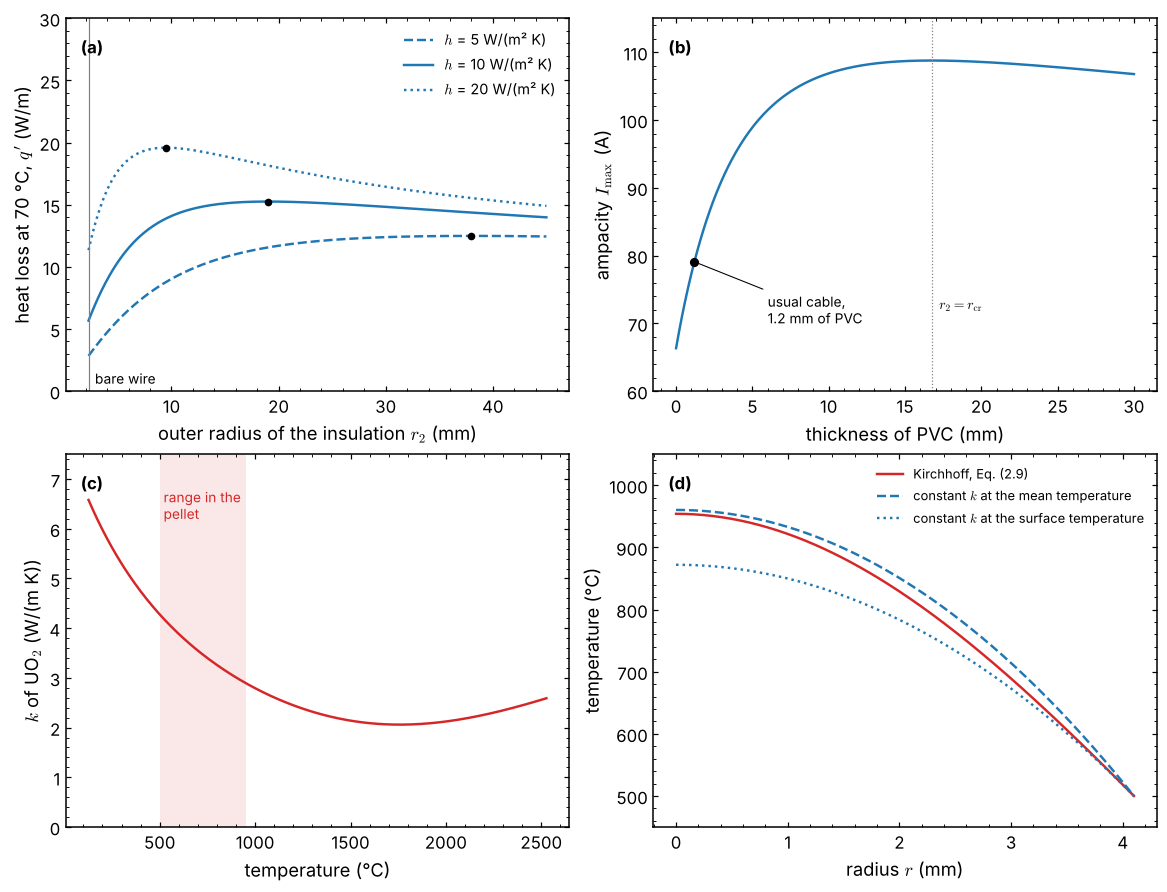

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))

ax = axes[0, 0]
r2 = np.linspace(r_c, 0.045, 400)
for hh, style in ((5.0, "C0--"), (10.0, "C0-"), (20.0, "C0:")):
    q = (T_max - T_amb) / np.array([R_cable(r, hh) for r in r2])
    ax.plot(r2 * 1e3, q, style, label=rf"$h$ = {hh:.0f} W/(m² K)")
    ax.plot(k_pvc / hh * 1e3, (T_max - T_amb) / R_cable(k_pvc / hh, hh), "ko", ms=4)
ax.axvline(r_c * 1e3, color="0.5", lw=0.8)
ax.text(r_c * 1e3 + 0.6, 0.6, "bare wire", fontsize=9)
ax.set_xlabel(r"outer radius of the insulation $r_2$ (mm)")
ax.set_ylabel(r"heat loss at 70 °C, $q'$ (W/m)")
ax.set_ylim(0, 30)
ax.legend(loc="upper right")
panel_label(ax, "(a)")

ax = axes[0, 1]
t_pvc = np.linspace(0, 0.03, 301)
ax.plot(t_pvc * 1e3, [ampacity(r_c + t) for t in t_pvc], "C0")
ax.plot(1.2, ampacity(r_c + 1.2e-3), "ko", ms=5)
ax.annotate("usual cable,\n1.2 mm of PVC", (1.2, ampacity(r_c + 1.2e-3)), (6, 70), fontsize=9,
            arrowprops=dict(arrowstyle="-", lw=0.7))
ax.axvline((r_cr - r_c) * 1e3, color="0.5", lw=0.8, ls=":")
ax.text((r_cr - r_c) * 1e3 + 0.5, 72, r"$r_2 = r_{\rm cr}$", fontsize=9)
ax.set_xlabel("thickness of PVC (mm)")
ax.set_ylabel(r"ampacity $I_{\max}$ (A)")
ax.set_ylim(60, 115)
panel_label(ax, "(b)")

ax = axes[1, 0]
TT = np.linspace(400, 2800, 300)
ax.plot(TT - 273.15, properties.uo2_conductivity(TT), "C3")
ax.axvspan(T_s - 273.15, T_c - 273.15, color="C3", alpha=0.1, lw=0)
ax.text(T_s - 273.15 + 20, 6.2, "range in the\npellet", fontsize=9, color="C3")
ax.set_xlabel("temperature (°C)")
ax.set_ylabel(r"$k$ of UO$_2$ (W/(m K))")
ax.set_ylim(0, 7.5)
panel_label(ax, "(c)")

ax = axes[1, 1]
r = np.linspace(0, R_p, 200)
T_exact = T_from_Theta(q_lin / (4 * math.pi) * (1 - r**2 / R_p**2))
k_mean = properties.uo2_conductivity(0.5 * (T_c_mean + T_s))
ax.plot(r * 1e3, T_exact - 273.15, "C3", label="Kirchhoff, Eq. (2.9)")
ax.plot(r * 1e3, T_s - 273.15 + q_lin / (4 * math.pi * k_mean) * (1 - r**2 / R_p**2), "C0--",
        label="constant $k$ at the mean temperature")
ax.plot(r * 1e3, T_s - 273.15 + q_lin / (4 * math.pi * k_s) * (1 - r**2 / R_p**2), "C0:",
        label="constant $k$ at the surface temperature")
ax.set_xlabel(r"radius $r$ (mm)")
ax.set_ylabel("temperature (°C)")
ax.set_ylim(450, 1050)
ax.legend(loc="upper right", fontsize=8.5)
panel_label(ax, "(d)")
plt.show()

**Figure 2.2.** (a) Heat loss per metre of a 16 mm² copper conductor at 70 °C covered with
PVC, against the outer radius of the insulation, for three air-side coefficients; the
dots are at the critical radius $k/h$. (b) Largest steady current of the same cable
against the thickness of PVC, $h = 10$ W/(m² K). (c) Thermal conductivity of uranium
dioxide (Fink 2000); the band is the range of temperature in the pellet. (d) Temperature
in a fuel pellet generating 20 kW/m with its surface at 500 °C: exact, from the Kirchhoff
transform, and with a constant conductivity.

## 2.5 Checks

`reference.steady_conduction_fv` solves the steady conduction equation by finite volumes
for a wall, a cylinder or a sphere, with layers of different conductivity, heat
generation, a conductivity that depends on temperature, and boundary conditions of fixed
temperature, convection, radiation or symmetry. The nonlinear equations are solved by
Newton's method, and the heat generated is compared with the heat that leaves.

*The wall.* With the conductivity constant in each layer, the scheme uses the exact
resistance of each half cell, so it reproduces Eqs. (2.1) and (2.2) to rounding error.
This checks the bookkeeping of the layers and the surface films, not the discretisation.

*The fuel pellet.* Here the finite-volume solution has a real discretisation error,
because the conductivity varies inside each cell. It converges to the Kirchhoff solution
(2.9) with an error that falls as the square of the cell size (Figure 2.3a,b).

*The cable.* The finite-volume model of the copper (with the heat generated in it) and
the PVC, cooled by Eq. (2.3)'s outer coefficient, reproduces the parabola in the copper
and the logarithm in the PVC (Figure 2.3c).

*The shortcuts.* For the pellet, Figure 2.3d shows how far the two constant-$k$ estimates
of the centre temperature are from the exact one, as the power per metre rises.

In [7]:
# the wall: layers and surface films
faces, ks = [0.0], []
for _, L, k in layers:
    faces += list(np.linspace(faces[-1], faces[-1] + L, 21)[1:])
    ks += [k] * 20
fv_wall = reference.steady_conduction_fv(faces, np.array(ks), "plane",
                                         left=("convection", h_i, T_i), right=("convection", h_o, T_o))
U, q_wall, T_si = wall(layers)
print(f"wall: q'' finite volumes {fv_wall['Q_right']:.10f} W/m2, Eq. (2.1) {q_wall:.10f};"
      f" inner surface differs by {abs(fv_wall['T_left'] - T_si):.1e} K")

# the fuel pellet: convergence to the Kirchhoff solution
q_vol = q_lin / (math.pi * R_p**2)
cells = np.array([5, 10, 20, 40, 80, 160])
pellet_err = []
for n in cells:
    fv = reference.steady_conduction_fv(np.linspace(0, R_p, n + 1), lambda T, i: properties.uo2_conductivity(T),
                                        "cylinder", q_gen=q_vol, left=("symmetry",), right=("temperature", T_s))
    exact = T_from_Theta(q_lin / (4 * math.pi) * (1 - fv["r"]**2 / R_p**2))
    pellet_err.append(np.max(np.abs(fv["T"] - exact)))
fv_pellet = fv
order = -np.polyfit(np.log(cells[2:]), np.log(pellet_err[2:]), 1)[0]
print(f"pellet: largest error {pellet_err[0]:.2f} K with {cells[0]} cells, {pellet_err[-1]:.1e} K with"
      f" {cells[-1]}; observed order {order:.2f}; energy balance {fv_pellet['balance']:.1e} W/m")

# the cable: copper with heat generation, then PVC, cooled by h
r_2 = r_c + 1.2e-3
I = ampacity(r_2)
q_cable = I**2 * rho_e / A_cu
n_cu, n_pvc = 20, 40
faces_c = np.concatenate((np.linspace(0, r_c, n_cu + 1), np.linspace(r_c, r_2, n_pvc + 1)[1:]))
k_c = np.concatenate((np.full(n_cu, 400.0), np.full(n_pvc, k_pvc)))
gen = np.concatenate((np.full(n_cu, q_cable / A_cu), np.zeros(n_pvc)))
fv_cable = reference.steady_conduction_fv(faces_c, k_c, "cylinder", q_gen=gen, left=("symmetry",),
                                          right=("convection", h_air, T_amb))
T_wire = T_amb + q_cable * R_cable(r_2)


def cable_exact(r):
    out = np.where(r <= r_c, T_wire + q_cable / (4 * math.pi * 400.0) * (1 - r**2 / r_c**2),
                   T_wire - q_cable * np.log(np.maximum(r, r_c) / r_c) / (2 * math.pi * k_pvc))
    return out


print(f"cable: I = {I:.1f} A, q' = {q_cable:.3f} W/m; largest difference from Eqs. (2.3) and (2.7):"
      f" {np.max(np.abs(fv_cable['T'] - cable_exact(fv_cable['r']))):.1e} K;"
      f" energy balance {fv_cable['balance']:.1e} W/m")

# the shortcuts for the pellet, against the power per metre
powers = np.linspace(2e3, 45e3, 44)
dT_surface, dT_mean = [], []
for qq in powers:
    Tc_exact = T_from_Theta(qq / (4 * math.pi))
    dT_surface.append(T_s + qq / (4 * math.pi * k_s) - Tc_exact)
    Tm = brentq(lambda Tc: Tc - T_s - qq / (4 * math.pi * properties.uo2_conductivity(0.5 * (Tc + T_s))),
                T_s + 0.1, 3500.0)
    dT_mean.append(Tm - Tc_exact)
print(f"at 40 kW/m: constant k at the surface {np.interp(40e3, powers, dT_surface):+.0f} K,"
      f" at the mean temperature {np.interp(40e3, powers, dT_mean):+.0f} K")

wall: q'' finite volumes 12.2253861420 W/m2, Eq. (2.1) 12.2253861420; inner surface differs by 0.0e+00 K
pellet: largest error 27.22 K with 5 cells, 3.9e-02 K with 160; observed order 1.90; energy balance -4.3e-10 W/m
cable: I = 79.1 A, q' = 8.062 W/m; largest difference from Eqs. (2.3) and (2.7): 4.5e-06 K; energy balance 4.3e-12 W/m
at 40 kW/m: constant k at the surface -377 K, at the mean temperature +113 K


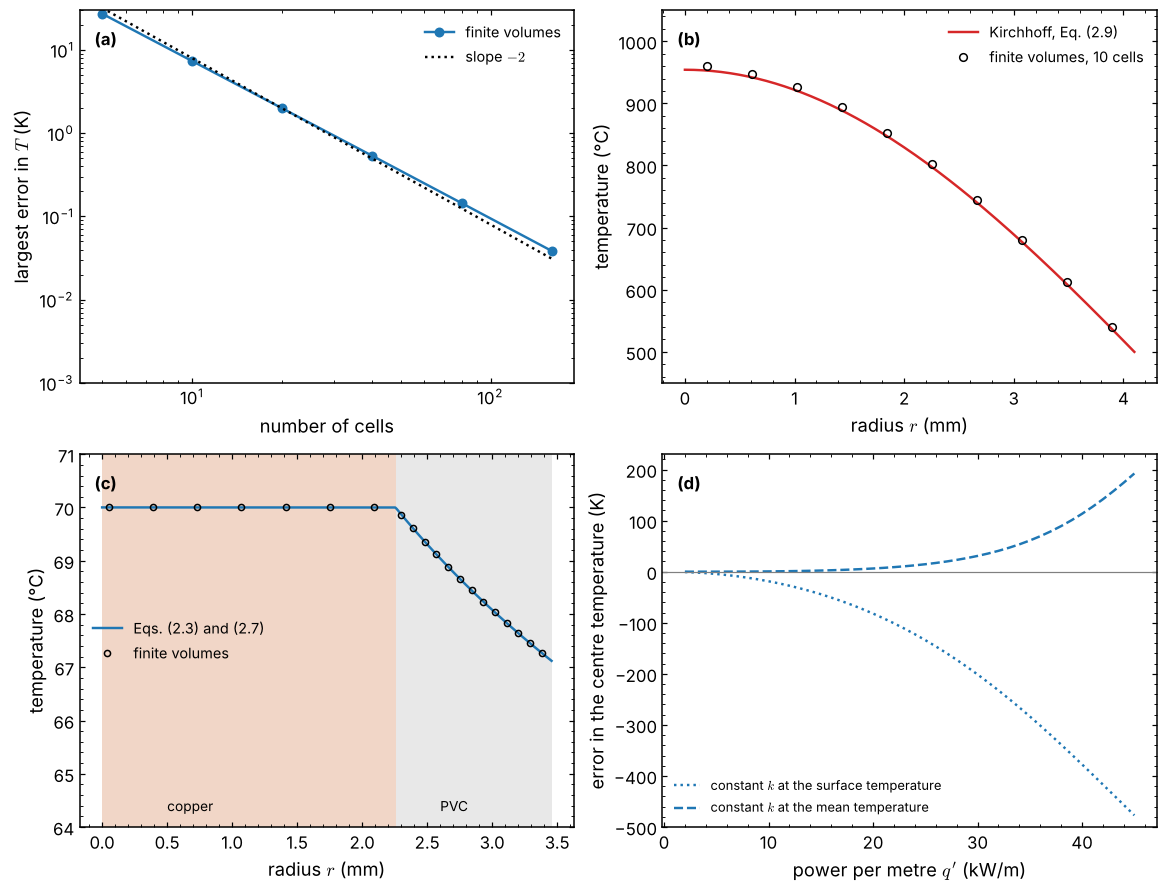

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
ax = axes[0, 0]
ax.loglog(cells, pellet_err, "o-", label="finite volumes")
ax.loglog(cells, pellet_err[2] * (cells[2] / cells) ** 2, "k:", label=r"slope $-2$")
ax.set_xlabel("number of cells")
ax.set_ylabel("largest error in $T$ (K)")
ax.set_ylim(1e-3, 30)
ax.legend(loc="upper right")
panel_label(ax, "(a)")

ax = axes[0, 1]
ax.plot(r * 1e3, T_exact - 273.15, "C3", label="Kirchhoff, Eq. (2.9)")
fv5 = reference.steady_conduction_fv(np.linspace(0, R_p, 11), lambda T, i: properties.uo2_conductivity(T),
                                     "cylinder", q_gen=q_vol, left=("symmetry",), right=("temperature", T_s))
ax.plot(fv5["r"] * 1e3, fv5["T"] - 273.15, "ko", ms=5, mfc="none", label="finite volumes, 10 cells")
ax.set_xlabel(r"radius $r$ (mm)")
ax.set_ylabel("temperature (°C)")
ax.set_ylim(450, 1050)
ax.legend(loc="upper right")
panel_label(ax, "(b)")

ax = axes[1, 0]
rr = np.linspace(0, r_2, 300)
ax.axvspan(0, r_c * 1e3, color="#d98c5f", alpha=0.35, lw=0)
ax.axvspan(r_c * 1e3, r_2 * 1e3, color="0.85", alpha=0.6, lw=0)
ax.plot(rr * 1e3, cable_exact(rr) - 273.15, "C0", label="Eqs. (2.3) and (2.7)")
ax.plot(fv_cable["r"][::3] * 1e3, fv_cable["T"][::3] - 273.15, "ko", ms=4, mfc="none", label="finite volumes")
ax.text(0.5, 64.3, "copper", fontsize=9)
ax.text(2.6, 64.3, "PVC", fontsize=9)
ax.set_xlabel(r"radius $r$ (mm)")
ax.set_ylabel("temperature (°C)")
ax.set_ylim(64, 71)
ax.legend(loc="center left")
panel_label(ax, "(c)")

ax = axes[1, 1]
ax.plot(powers / 1e3, dT_surface, "C0:", label="constant $k$ at the surface temperature")
ax.plot(powers / 1e3, dT_mean, "C0--", label="constant $k$ at the mean temperature")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel(r"power per metre $q'$ (kW/m)")
ax.set_ylabel("error in the centre temperature (K)")
ax.set_ylim(-500, 230)
ax.legend(loc="lower left", fontsize=8.5)
panel_label(ax, "(d)")
plt.show()

**Figure 2.3.** Checks. (a) Largest error of the finite-volume temperature in the fuel
pellet against the number of cells; the dotted line has slope −2. (b) The pellet profile:
the Kirchhoff solution (2.9) and finite volumes with 10 cells. (c) Temperature in the
cable carrying its ampacity, from the analytical profiles (parabola in the copper,
logarithm in the PVC) and from finite volumes; the copper is isothermal to a few
thousandths of a kelvin. (d) Error of the centre temperature of the pellet when the
conductivity is taken constant, against the power per metre.

The finite volumes reproduce the wall to rounding error, the cable to $10^{-5}$ K, and
the pellet with a second-order error that is 0.04 K with 160 cells. The energy balances
close to $10^{-10}$ W/m or better. Figure 2.3d shows the price of the constant-$k$
shortcuts for the pellet. With $k$ taken at the surface, the centre comes out too cold,
which is the dangerous side: by 82 K at 20 kW/m and by 377 K at 40 kW/m. With $k$ taken at
the mean temperature the error has the other sign and is small at low power, 6 K at
20 kW/m, but grows to 113 K at 40 kW/m, where the centre reaches the temperatures at which
the conductivity of uranium dioxide stops falling. Neither shortcut can be trusted without
the exact answer to compare with.

## 2.6 What to trust

* *Material properties.* For the wall, the answers are only as good as the conductivities,
  and those of masonry and insulation depend on moisture: wet brick conducts twice as well
  as dry. The ±10–20 % spread of real materials gives the same spread in $U$.
* *Two-dimensional effects.* A real wall has corners, window frames and the edges of floor
  slabs, where heat flows around the insulation. These *thermal bridges* can add a third to
  the loss of a well-insulated house; Chapter 3 computes one, a balcony slab.
* *The combined coefficient of the cable.* Taking $h = 10$ W/(m² K) for convection and
  radiation together is a guess at the 10–20 % level. Cables in a bundle, in a conduit or
  in sunlight are much worse cooled, and standards reduce their ampacity accordingly.
* *The fuel pellet.* The conductivity used is for fresh fuel. Irradiation, fission
  products and cracks lower it, and the gap between the pellet and its cladding adds a
  resistance that depends on the history of the rod (Exercise 3). The point of the section
  is the method: with $k(T)$, integrate the conductivity, do not average it.

## Summary

* For steady one-dimensional conduction without generation, each layer is a resistance:
  $L/kA$ for a plane wall, $\ln(r_2/r_1)/2\pi kL$ for a cylinder; surface films add $1/hA$;
  resistances in series add, Eq. (2.1).
* The inner surface temperature of a wall, Eq. (2.2), decides comfort and condensation.
* Insulating a cylinder thinner than the critical radius $r_{\rm cr} = k/h$ increases its
  heat loss, which helps electric cables to carry more current, Eqs. (2.4)–(2.5).
* With heat generation $\dot q$, the centre of a cylinder is $q'/4\pi k$ hotter than its
  surface, whatever its radius, Eq. (2.7).
* With $k(T)$, the Kirchhoff transform $\Theta = \int k\,dT$ turns the conduction equation
  into one with constant conductivity; the conductivity integral from surface to centre of
  a fuel pellet is $q'/4\pi$, Eq. (2.9).

## Exercises

Sample solutions are in [`solutions/part1_conduction/02_solutions.ipynb`](../../solutions/part1_conduction/02_solutions.ipynb).

1. **A window.** Double glazing is two panes of glass, 4 mm thick with $k = 1.0$ W/(m K),
   separated by a 16 mm layer of air. Treat the air as a still layer that conducts,
   $k = 0.025$ W/(m K), and find $U$ and the temperature of the inner pane for the
   conditions of Section 2.1. Compare with single glazing. Will the inner pane mist up?
   Real double glazing has $U \approx 2.8$ W/(m² K): what has the conduction-only model
   left out?
2. **A sphere.** Show that the critical radius of a spherical shell of insulation is
   $r_{\rm cr} = 2k/h$. A thermistor bead of radius 0.5 mm, used to measure air
   temperature, dissipates 2 mW of electrical power, which warms it above the air
   ($h = 50$ W/(m² K)). Find this self-heating error for the bare bead, and for the bead
   coated with epoxy ($k = 0.2$ W/(m K)) to radii of 1, 2 and 8 mm. Does the coating make
   the reading better or worse?
3. **The whole fuel rod.** The pellet of Section 2.4 sits inside a zirconium-alloy tube
   (inner radius 4.18 mm, outer radius 4.75 mm, $k = 16$ W/(m K)), with a gas-filled gap
   between pellet and tube of conductance $h_g = 5000$ W/(m² K), and is cooled by water at
   310 °C with $h = 30\,000$ W/(m² K). For $q' = 20$ kW/m, find the temperatures of the
   water-side surface, the inner surface of the tube, the pellet surface and the pellet
   centre. Which resistance matters most outside the pellet?
4. **The insulation of Chapter 1 again.** Mineral wool conducts better when it is warm.
   Suppose $k = 0.036$ W/(m K) at 0 °C, rising linearly to 0.050 W/(m K) at 100 °C. Use the
   mean-temperature rule, which is exact for a linear $k(T)$, to find the heat loss of the
   district-heating pipe of Chapter 1, and compare it with the 63.7 W/m found with
   $k = 0.045$ W/(m K). Check your answer with `reference.steady_conduction_fv`.

## Suggested references

* T. L. Bergman, A. S. Lavine, F. P. Incropera and D. P. DeWitt, *Fundamentals of Heat
  and Mass Transfer*, 8th ed. (Wiley, 2017).
* H. S. Carslaw and J. C. Jaeger, *Conduction of Heat in Solids*, 2nd ed. (Oxford
  University Press, 1959).
* J. K. Fink, "Thermophysical properties of uranium dioxide", *J. Nucl. Mater.* **279**,
  1 (2000).
* O. A. Alduchov and R. E. Eskridge, "Improved Magnus form approximation of saturation
  vapor pressure", *J. Appl. Meteor.* **35**, 601 (1996).
* IEC 60028, *International standard of resistance for copper* (International
  Electrotechnical Commission, 1925).

---

**Previous:** [1. Heat balances and the three modes of heat transfer](01_heat_balances.ipynb) &nbsp;·&nbsp; **Next:** [3. Fins and extended surfaces](03_fins.ipynb)